In [1]:
from pathlib import Path
from bisect import bisect_right

import numpy as np
from matplotlib import pyplot as plt

# Data exported from the original HDF5 file. The image tensor is split into
# sequential chunks so each file is easier to upload/download.
data_dir = Path("rocket_piston_simulations")

In [2]:
inputs = np.load(data_dir / "inputs.npy", mmap_mode="r")
outputs = np.load(data_dir / "output_scalars.npy", mmap_mode="r")
input_names = np.load(data_dir / "inputs_names.npy")
output_names = np.load(data_dir / "output_scalars_names.npy")

image_paths = sorted(data_dir.glob("output_images_chunk_*_of_10.npy"))
image_chunks = [np.load(path, mmap_mode="r") for path in image_paths]
chunk_starts = np.cumsum([0] + [chunk.shape[0] for chunk in image_chunks])

print("inputs:", inputs.shape, inputs.dtype)
print("outputs:", outputs.shape, outputs.dtype)
print("image chunks:", len(image_chunks), image_chunks[0].shape[1:], image_chunks[0].dtype)
print("total image rows:", chunk_starts[-1])
assert len(input_names) == inputs.shape[1]
assert len(output_names) == outputs.shape[1]
assert inputs.shape[0] == outputs.shape[0] == chunk_starts[-1]

inputs: (492901, 28) float32
outputs: (492901, 12) float32
image chunks: 10 (3, 2, 32, 32) float32
total image rows: 492901


In [3]:
def load_image(index):
    """Return one image sample from the chunked image files."""
    chunk_idx = bisect_right(chunk_starts, index) - 1
    local_idx = index - chunk_starts[chunk_idx]
    return image_chunks[chunk_idx][local_idx]


def load_images(indices):
    """Return image samples for a small list/array of global row indices."""
    return np.stack([load_image(int(index)) for index in indices])

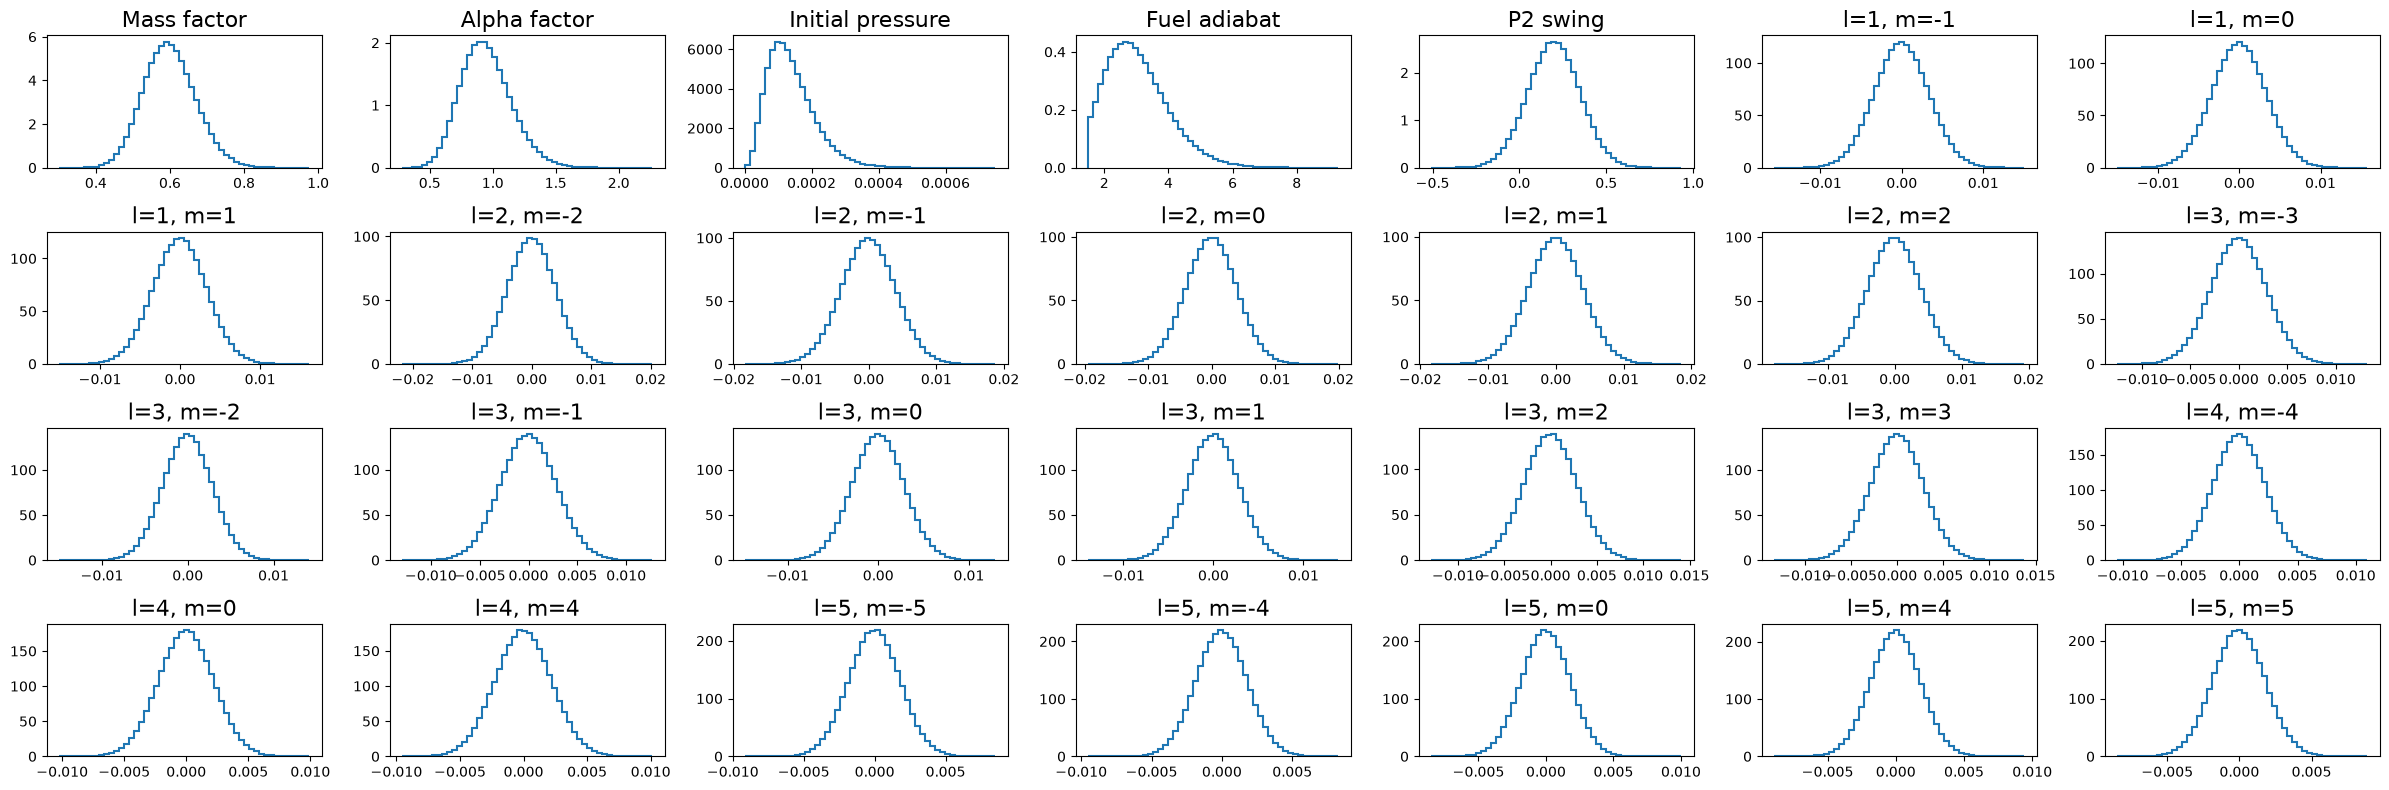

In [4]:
# Input parameter distributions.
fig, axes = plt.subplots(4, 7, figsize=(24, 8))
for i, ax in enumerate(axes.flatten()):
    ax.set_title(input_names[i], fontsize=16)
    ax.hist(inputs[:, i], bins=50, density=True, histtype="step", linewidth=1.5)

plt.tight_layout()

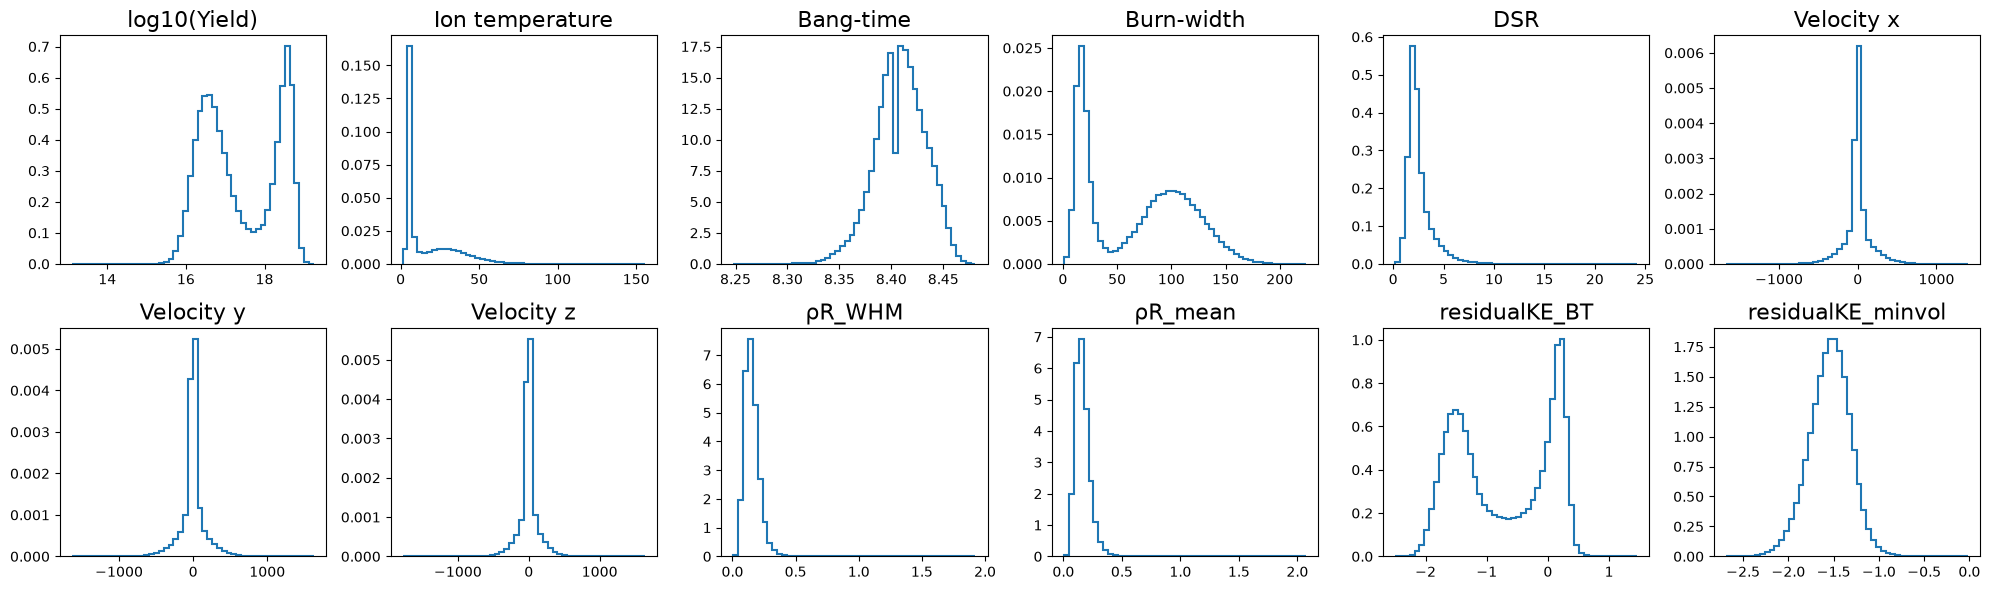

In [5]:
# Scalar output distributions.
fig, axes = plt.subplots(2, 6, figsize=(20, 6))
for i, ax in enumerate(axes.flatten()):
    ax.set_title(output_names[i], fontsize=16)
    ax.hist(outputs[:, i], bins=50, density=True, histtype="step", linewidth=1.5)

plt.tight_layout()

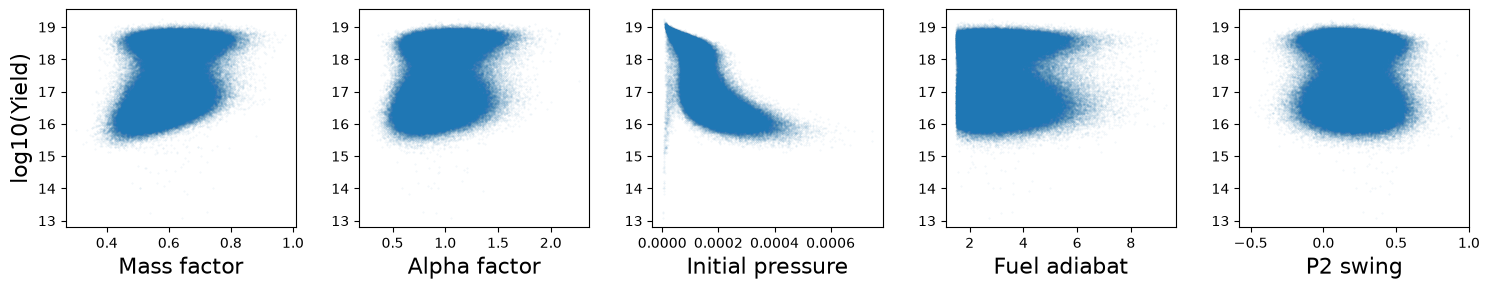

In [6]:
# Relationship between yield and the first five input parameters.
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i, ax in enumerate(axes.flatten()):
    ax.set_xlabel(input_names[i], fontsize=16)
    ax.scatter(inputs[:, i], outputs[:, 0], s=0.1, alpha=0.1)
axes[0].set_ylabel(output_names[0], fontsize=16)

plt.tight_layout()

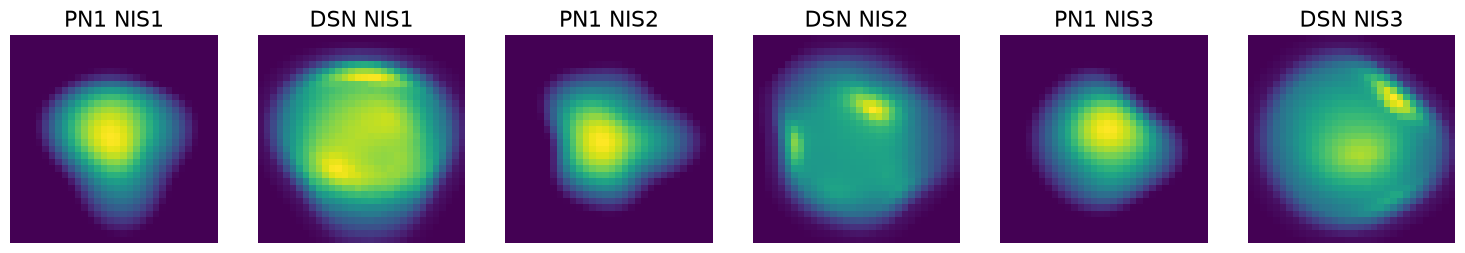

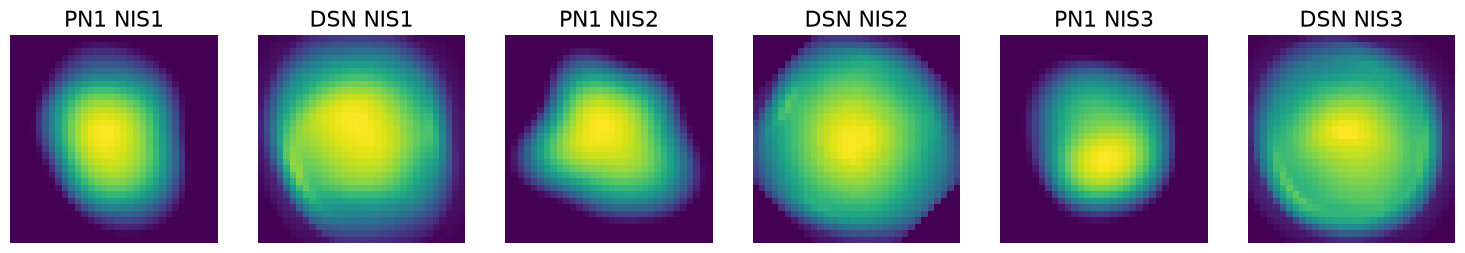

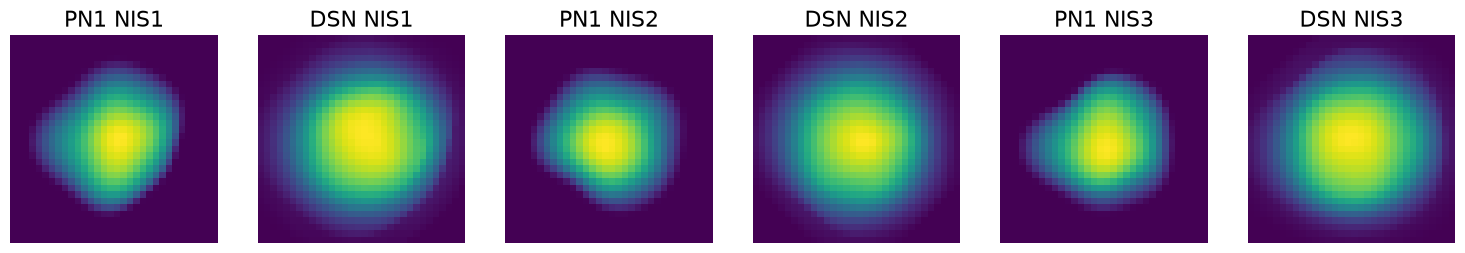

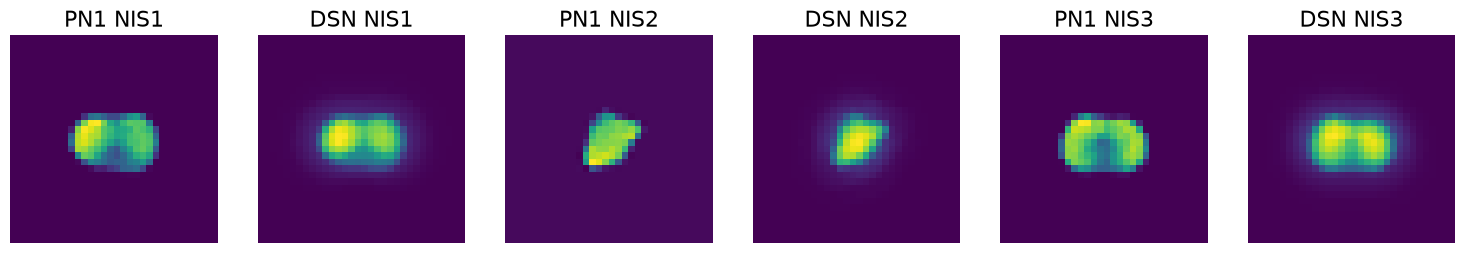

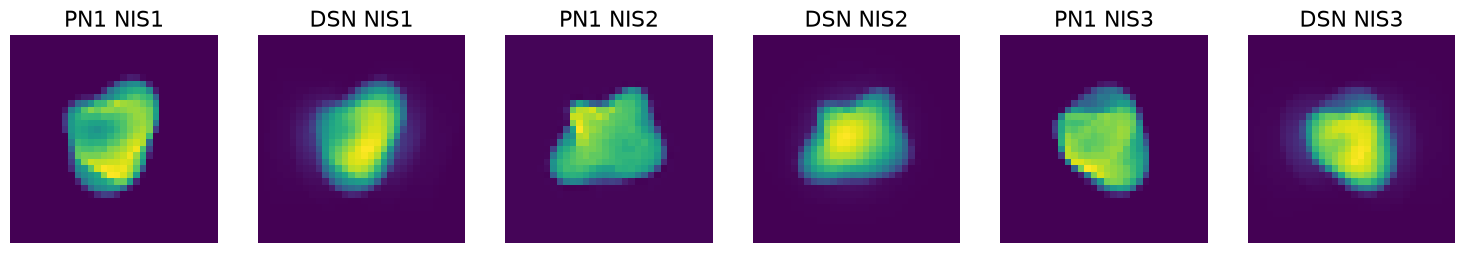

In [7]:
# Show example images across the range of yields without loading the full image tensor.
yields_ranked = np.argsort(outputs[:, 0])
example_indices = yields_ranked[10_000::100_000]

for image_idx in example_indices:
    image = load_image(image_idx)
    fig, axes = plt.subplots(1, 6, figsize=(15, 2.5))
    for i, ax in enumerate(axes):
        ax.imshow(image[i // 2, i % 2])
        ax.axis("off")
        title = f"{'DSN' if i % 2 else 'PN1'} NIS{i // 2 + 1}"
        ax.set_title(title, fontsize=16)
    axes[0].set_ylabel(f"log10(yield) = {outputs[image_idx, 0]:.1f}")
    plt.tight_layout()